# Question 1

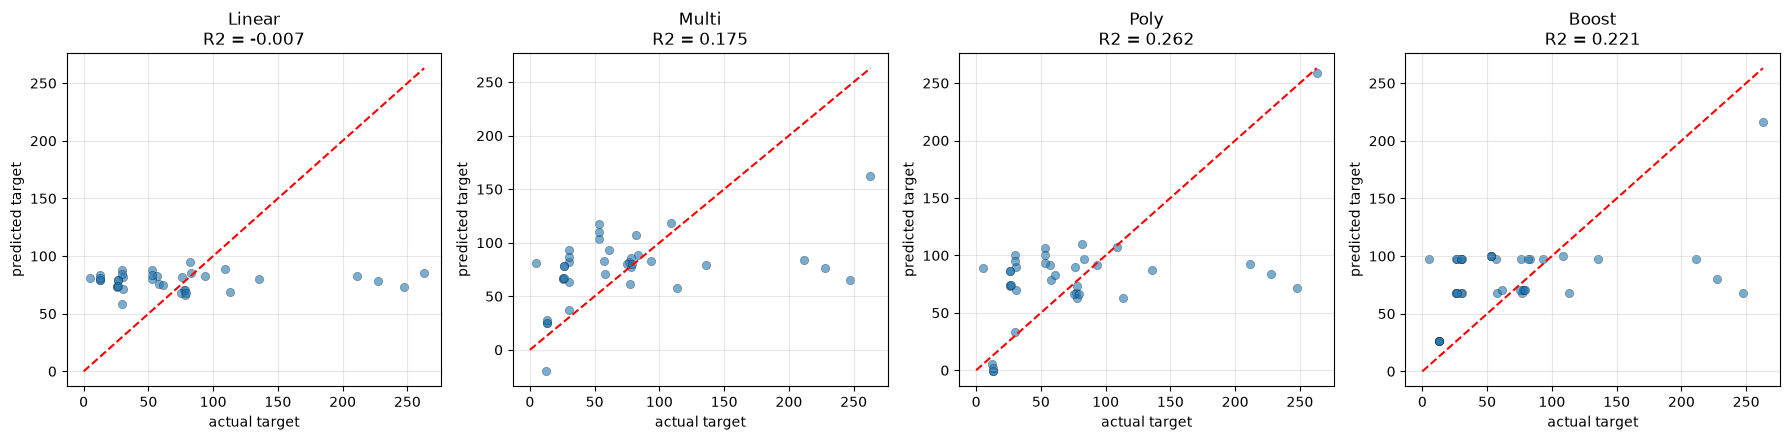

,model,R2
1,Poly,0.261776
2,Boost,0.220944
3,Multi,0.174589
4,Linear,-0.007045


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("titanic.csv")
df = df.dropna()

df = df.sample(frac=1, random_state=42)

x = df[["Age", "Pclass", "SibSp"]].values
y = df["Fare"].values

n = int(len(df)*0.8)
x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]


def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w


def boost(X_train, y_train, X_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(X_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for j in range(X_train.shape[1]):
            for t in np.unique(X_train[:, j])[:-1]:
                left = X_train[:, j] <= t
                right = X_train[:, j] > t
                a, b = error[left].mean(), error[right].mean()
                fix_train = np.where(left, a, b)
                loss = ((error - fix_train) ** 2).sum()
                if loss < best:
                    best, best_train, best_test = loss, fix_train, np.where(X_test[:, j] <= t, a, b)
        pred_train += 0.1 * best_train
        pred_test += 0.1 * best_test
    return pred_test
    
def r2(y_test, y_pred):
    return 1 - (((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum())


def show(pos, name, y_pred):
    plt.subplot(1, 4, pos)
    plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="k", linewidths=0.3)
    plt.plot([0, y_test.max()], [0, y_test.max()], "r--")
    plt.title(f"{name}\nR2 = {r2(y_test, y_pred):.3f}")
    plt.xlabel("actual " + "target")
    plt.ylabel("predicted " + "target")
    plt.grid(alpha=0.3)


preds = {
    "Linear": linear(x_train[:, :1], y_train, x_test[:, :1]),
    "Multi": linear(x_train, y_train, x_test),
    "Poly": linear(np.column_stack([x_train, x_train**2]), y_train, np.column_stack([x_test, x_test**2])),
    "Boost": boost(x_train, y_train, x_test),
}

plt.figure(figsize=(18, 4.5))
for pos, (name, y_pred) in enumerate(preds.items(), 1):
    show(pos, name, y_pred)
plt.tight_layout()
plt.show()

rank = pd.DataFrame({"model": list(preds), "R2": [r2(y_test, p) for p in preds.values()]})
rank = rank.sort_values("R2", ascending=False).reset_index(drop=True)
rank.index += 1
rank

# Question 2

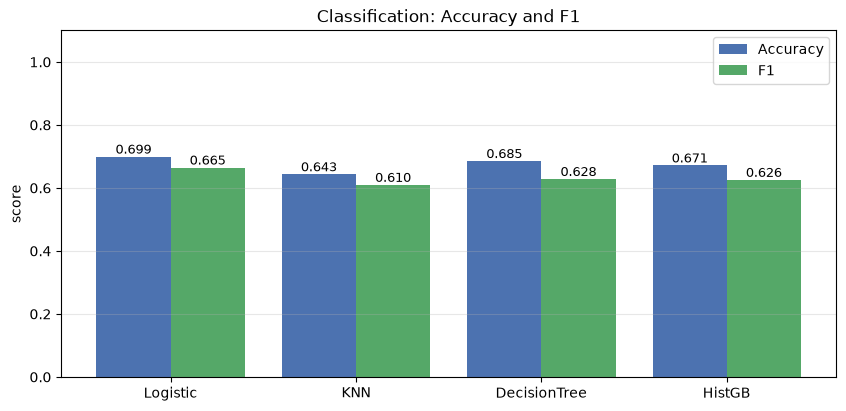

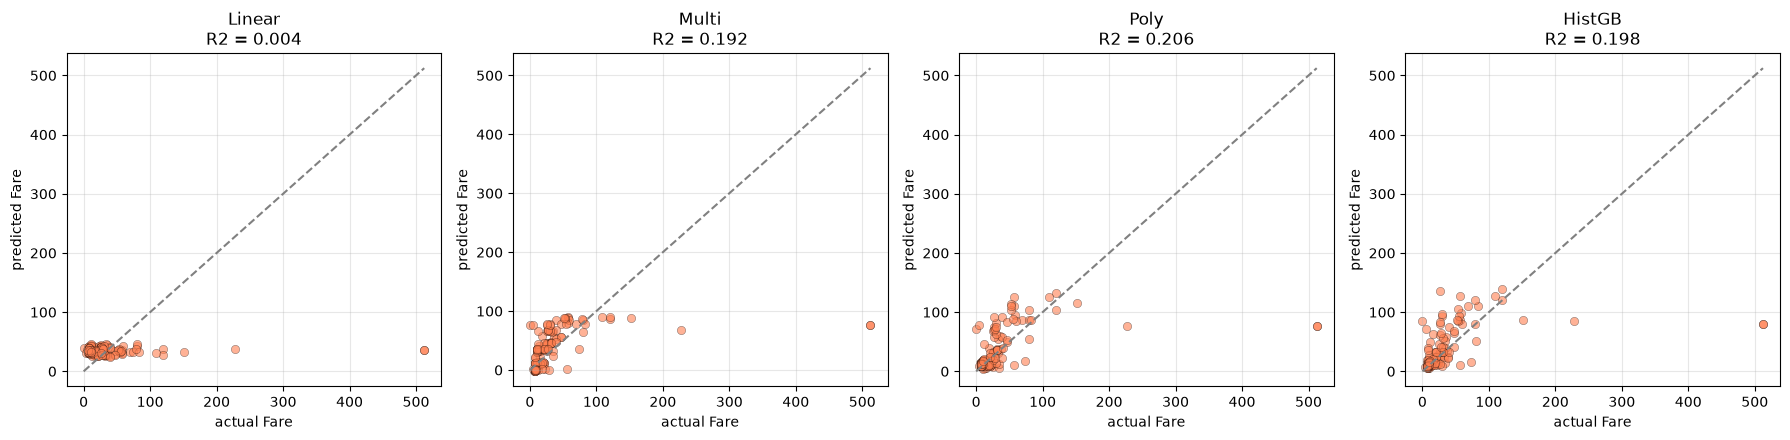

,model,R2
1,Poly,0.206002
2,HistGB,0.198495
3,Multi,0.192111
4,Linear,0.003810


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, r2_score

# 1. Load and clean
df = pd.read_csv("../titanic.csv")          # <<<
cols = ["Age", "Pclass", "SibSp"]           # <<<
cls_target, reg_target = "Survived", "Fare" # <<<
df = df[cols + [cls_target, reg_target]].dropna()

# 2. Split
x = df[cols]
y = df[[cls_target, reg_target]]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# ----------------- 1. CLASSIFICATION -----------------
best_cls = HistGradientBoostingClassifier(random_state=42)
classifiers = [
    ("Logistic", LogisticRegression(max_iter=1000)),
    ("KNN", KNeighborsClassifier()),
    ("DecisionTree", DecisionTreeClassifier(max_depth=4)),
    ("HistGB", best_cls),
]

cls_names, cls_acc, cls_f1 = [], [], []
for name, model in classifiers:
    pred = model.fit(x_train, y_train[cls_target]).predict(x_test)
    cls_names.append(name)
    cls_acc.append(accuracy_score(y_test[cls_target], pred))
    cls_f1.append(f1_score(y_test[cls_target], pred, average="macro"))

# Add predicted class to x
x_test["pred_class"] = best_cls.predict(x_test)
x_train["pred_class"] = cross_val_predict(best_cls, x_train, y_train[cls_target], cv=5)
all_cols = cols + ["pred_class"]

# ----------------- 2. REGRESSION -----------------
regressors = [
    ("Linear", LinearRegression(), cols[:1]),
    ("Multi", LinearRegression(), all_cols),
    ("Poly", make_pipeline(PolynomialFeatures(2), LinearRegression()), all_cols),
    ("HistGB", HistGradientBoostingRegressor(random_state=42), all_cols),
]
reg_preds = {}
for name, model, c in regressors:
    reg_preds[name] = model.fit(x_train[c], y_train[reg_target]).predict(x_test[c])

pos = np.arange(len(cls_names))
plt.figure(figsize=(10, 4.5))
b1 = plt.bar(pos - 0.2, cls_acc, 0.4, label="Accuracy", color="#4C72B0")
b2 = plt.bar(pos + 0.2, cls_f1, 0.4, label="F1", color="#55A868")
plt.bar_label(b1, fmt="%.3f", fontsize=9)
plt.bar_label(b2, fmt="%.3f", fontsize=9)
plt.xticks(pos, cls_names)
plt.ylim(0, 1.1)
plt.ylabel("score")
plt.title("Classification: Accuracy and F1")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

cls_rank = pd.DataFrame({"model": cls_names, "accuracy": cls_acc, "F1": cls_f1})
cls_rank = cls_rank.sort_values("accuracy", ascending=False).reset_index(drop=True)
cls_rank.index += 1
cls_rank

# _______________________________________________________________________

y_true = y_test[reg_target]
plt.figure(figsize=(18, 4.5))
for i, (name, p) in enumerate(reg_preds.items(), 1):
    plt.subplot(1, 4, i)
    plt.scatter(y_true, p, alpha=0.6, color="coral", edgecolors="k", linewidths=0.3)
    plt.plot([0, y_true.max()], [0, y_true.max()], "gray", linestyle="--")
    plt.title(f"{name}\nR2 = {r2_score(y_true, p):.3f}")
    plt.xlabel("actual " + reg_target)
    plt.ylabel("predicted " + reg_target)
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

reg_rank = pd.DataFrame({"model": list(reg_preds), "R2": [r2_score(y_true, p) for p in reg_preds.values()]})
reg_rank = reg_rank.sort_values("R2", ascending=False).reset_index(drop=True)
reg_rank.index += 1
reg_rank
